# Recognising activities from phone motion with a hand-built HMM

I recorded the accelerometer and gyroscope of a phone while standing, walking, jumping and lying still, and built a Gaussian Hidden Markov Model in NumPy to guess the activity. Baum-Welch trains it and Viterbi decodes it. No HMM library is used.

The notebook goes: load the data, turn windows of signal into features, build the HMM, choose which features to keep, train, test on recordings the model never saw, and finally see how noise and sampling rate affect it. It runs top to bottom on the CSV files in `data/`.

## 0. Setup

In [1]:
from itertools import product
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 8, "axes.titlesize": 9, "legend.fontsize": 7})

FS = 50            # every recording is resampled to 50 Hz
WIN_S = 2.0        # window length in seconds
OVERLAP = 0.5      # consecutive windows overlap by half
ACTIVITIES = ["standing", "walking", "jumping", "still"]      # the hidden states, in this order
SEED = 42

K = len(ACTIVITIES)
SENSOR_COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
EPS = 1e-8
STATE_COLORS = ["#4C78A8", "#F58518", "#E45756", "#72B7B2"]

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_DIR, TEST_DIR, FIG_DIR = ROOT / "data" / "train", ROOT / "data" / "test", ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Data

Each CSV has a timestamp plus `ax ay az gx gy gz`. The accelerometer is the one that includes gravity (in g, iPhone convention) and the gyroscope is in rad/s. The activity comes from the file name (`walking_r1_03.csv`). The one multi-activity session carries a `label` column instead, and rows where I was picking up the phone or switching activity have an empty label and are ignored.

Phones log at slightly uneven intervals (about 100 Hz here), so every recording is interpolated onto an even 50 Hz grid using its own timestamps. `data/manifest.csv` records which phone and which original recording each file came from.

In [2]:
def to_seconds(t):
    """Timestamps may be s, ms, us or ns; return seconds since the first sample."""
    t = np.asarray(t, dtype=float)
    m = np.nanmax(np.abs(t))
    scale = 1e-9 if m > 1e17 else 1e-6 if m > 1e14 else 1e-3 if m > 1e11 else 1.0
    return (t - t[0]) * scale

def load_recording(path, fs=FS):
    path = Path(path)
    df = pd.read_csv(path)
    missing = [c for c in ["time"] + SENSOR_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"{path.name}: missing columns {missing}")
    if df["time"].isna().any():
        raise ValueError(f"{path.name}: missing timestamps")
    df = df.sort_values("time").drop_duplicates("time").reset_index(drop=True)
    t = to_seconds(df["time"].to_numpy())
    n_nan = int(df[SENSOR_COLS].isna().sum().sum())
    df[SENSOR_COLS] = df[SENSOR_COLS].interpolate(limit_direction="both")

    t_new = np.arange(0, t[-1], 1 / fs)
    X = np.column_stack([np.interp(t_new, t, df[c].to_numpy()) for c in SENSOR_COLS])

    if "label" in df.columns:                              # multi-activity session
        idx = np.clip(np.searchsorted(t, t_new), 0, len(t) - 1)
        raw = df["label"].to_numpy()[idx]
        y = np.array([ACTIVITIES.index(v.strip().lower()) if isinstance(v, str) and v.strip() else -1 for v in raw])
    else:                                                  # label from the file name
        act = path.stem.split("_")[0].lower()
        if act not in ACTIVITIES:
            raise ValueError(f"{path.name}: can't read the activity from the file name")
        y = np.full(len(t_new), ACTIVITIES.index(act))
    return dict(name=path.stem, t=t_new, X=X, y=y, native_fs=1 / np.median(np.diff(t)),
                n_nan=n_nan, duration=t_new[-1])

def load_dir(d):
    return [load_recording(f) for f in sorted(Path(d).glob("*.csv"))]

manifest = pd.read_csv(ROOT / "data" / "manifest.csv")
GROUP = dict(zip(manifest["file"].str.replace(".csv", "", regex=False), manifest["group"]))

train_recs, test_recs = load_dir(TRAIN_DIR), load_dir(TEST_DIR)
for r in train_recs + test_recs:
    r["group"] = GROUP[r["name"]]
print(f"{len(train_recs)} training files, {len(test_recs)} test files")
print("native sampling rates found:", sorted({round(r["native_fs"]) for r in train_recs + test_recs}), "Hz  ->  resampled to", FS, "Hz")
print("missing values:", sum(r["n_nan"] for r in train_recs + test_recs))
display(manifest.groupby(["group", "device", "platform", "recorded"]).agg(files=("file", "count")).reset_index())

def seconds(recs, group=None):
    return [round(sum((r["y"] == k).sum() for r in recs if group is None or r["group"] == group) / FS, 1) for k in range(K)]
display(pd.DataFrame({"train": seconds(train_recs), "test A": seconds(test_recs, "A"), "test B": seconds(test_recs, "B")},
                     index=ACTIVITIES).rename_axis("seconds of data"))

56 training files, 16 test files
native sampling rates found: [100, 102] Hz  ->  resampled to 50 Hz
missing values: 0


,group,device,platform,recorded,files
0,A,iPhone 11,ios,2026-10-26,12
1,B,SM-A235F,android,2026-10-27,2
2,B,iPhone 16 Pro,ios,2026-10-27,2
3,train,iPhone 11 Pro,ios,2026-10-26,56


,train,test A,test B
seconds of data,,,
standing,133.5,24.0,8.3
walking,130.0,24.0,8.8
jumping,109.5,24.0,5.7
still,126.5,24.0,6.8


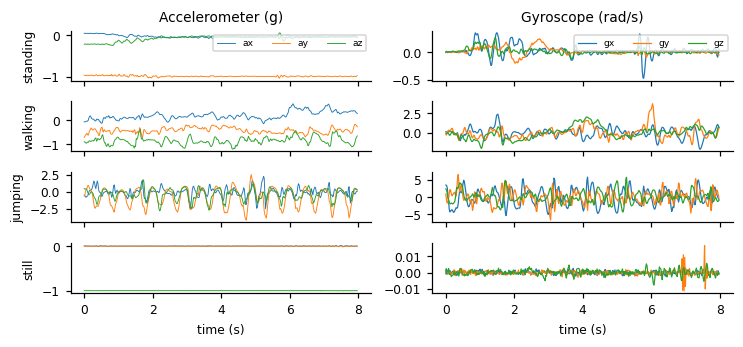

In [3]:
fig, axes = plt.subplots(K, 2, figsize=(6.8, 3.2), sharex=True)
for row, act in enumerate(ACTIVITIES):
    r = next(r for r in train_recs if r["name"].startswith(act + "_"))
    for j, lab in enumerate(["ax", "ay", "az"]):
        axes[row, 0].plot(r["t"], r["X"][:, j], lw=0.6, label=lab)
    for j, lab in enumerate(["gx", "gy", "gz"]):
        axes[row, 1].plot(r["t"], r["X"][:, 3 + j], lw=0.8, label=lab)
    axes[row, 0].set_ylabel(act)
axes[0, 0].set_title("Accelerometer (g)"); axes[0, 1].set_title("Gyroscope (rad/s)")
axes[0, 0].legend(ncol=3, fontsize=6, loc="upper right"); axes[0, 1].legend(ncol=3, fontsize=6, loc="upper right")
axes[-1, 0].set_xlabel("time (s)"); axes[-1, 1].set_xlabel("time (s)")
fig.tight_layout(); savefig(fig, "sample_data"); plt.show()

## 2. Features

I cut each recording into 2 s windows that overlap by half (100 samples). Two seconds is long enough to catch 3 to 4 cycles of walking or jumping, which the FFT needs, and short enough to follow a change of activity. Each window becomes one vector of 15 features. Below, `mag` is the length of the acceleration vector and `gmag` the length of the gyroscope vector.

| Feature | What it captures |
|---|---|
| `acc_mag_mean` | average acceleration load |
| `acc_mag_logvar` | how much the movement varies (log, because it spans many orders of magnitude) |
| `acc_sma` | signal magnitude area: overall movement, mean of abs(ax)+abs(ay)+abs(az) |
| `acc_corr_xy/xz/yz` | how the axes move together (jumping couples y and z strongly, walking barely) |
| `acc_mean_x/y/z` | direction of gravity, i.e. how the phone is held |
| `gyr_mag_mean`, `gyr_mag_logvar` | how much the phone rotates |
| `acc_dom_freq` | the strongest frequency in the 0.5 to 10 Hz band, i.e. how fast the movement repeats |
| `acc_spec_energy` | log of the spectral power in that band |
| `acc_spec_entropy` | peaky spectrum (rhythmic movement) vs flat spectrum (noise) |
| `gyr_spec_energy` | the same energy measure for the gyroscope |

`acc_dom_freq` only means something for rhythmic movement. For still and standing it just picks a random noise peak (around 6 Hz in my data), so the model should lean on the other features there.

**Normalisation.** The features sit on very different scales (g, correlations, log-powers), and Gaussian emissions plus the variance floor in EM care about scale, so every feature is z-scored: `(x - mean) / std`. The mean and std come from the **training data only** and are reused as they are on the test data. I picked z-score over min-max because a few extreme jumping windows would squash the min-max range for everything else.

In [4]:
NFFT = 512      # zero-padded FFT length, gives a finer frequency grid

def power_spectrum(x, fs):
    x = x - x.mean()
    w = np.hanning(len(x))
    P = np.abs(np.fft.rfft(x * w, n=NFFT)) ** 2 / (np.sum(w ** 2) * fs)
    return np.fft.rfftfreq(NFFT, 1 / fs), P

def safe_corr(a, b):
    if a.std() < 1e-9 or b.std() < 1e-9:
        return 0.0
    return float(np.mean((a - a.mean()) * (b - b.mean())) / (a.std() * b.std()))

FEATURE_NAMES = ["acc_mag_mean", "acc_mag_logvar", "acc_sma",
                 "acc_corr_xy", "acc_corr_xz", "acc_corr_yz",
                 "acc_mean_x", "acc_mean_y", "acc_mean_z",
                 "gyr_mag_mean", "gyr_mag_logvar",
                 "acc_dom_freq", "acc_spec_energy", "acc_spec_entropy", "gyr_spec_energy"]

def window_features(acc, gyr, fs):
    mag, gmag = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    f = {}
    f["acc_mag_mean"] = mag.mean()
    f["acc_mag_logvar"] = np.log(mag.var() + EPS)
    f["acc_sma"] = np.abs(acc).sum(axis=1).mean()
    f["acc_corr_xy"], f["acc_corr_xz"], f["acc_corr_yz"] = (safe_corr(acc[:, 0], acc[:, 1]),
                                                           safe_corr(acc[:, 0], acc[:, 2]),
                                                           safe_corr(acc[:, 1], acc[:, 2]))
    f["acc_mean_x"], f["acc_mean_y"], f["acc_mean_z"] = acc.mean(axis=0)
    f["gyr_mag_mean"] = gmag.mean()
    f["gyr_mag_logvar"] = np.log(gmag.var() + EPS)
    freqs, P = power_spectrum(mag, fs)
    band = (freqs >= 0.5) & (freqs <= min(10.0, fs / 2))
    Pb = P[band]
    f["acc_dom_freq"] = freqs[band][np.argmax(Pb)]
    f["acc_spec_energy"] = np.log(Pb.sum() + EPS)
    p = Pb / (Pb.sum() + EPS)
    f["acc_spec_entropy"] = -np.sum(p * np.log(p + EPS)) / np.log(len(p))
    f["gyr_spec_energy"] = np.log(power_spectrum(gmag, fs)[1][band].sum() + EPS)
    return np.array([f[n] for n in FEATURE_NAMES])

def decimate(X, y, factor):
    """Average blocks of `factor` samples (a lower sampling rate, with a crude low-pass)."""
    if factor == 1:
        return X, y
    n = len(X) // factor * factor
    return X[:n].reshape(-1, factor, X.shape[1]).mean(axis=1), y[:n:factor]

def build_sequences(recs, factor=1, noise_sd=0.0, noise_rng=None):
    """One sequence of windows per recording. Windows that touch an unlabelled stretch are skipped."""
    fs = FS // factor
    win = int(round(WIN_S * fs)); step = max(1, int(round(win * (1 - OVERLAP))))
    seqs = []
    for r in recs:
        X = r["X"]
        if noise_sd > 0:      # sensor noise: full size on the accelerometer, a tenth of it on the gyroscope
            X = X + noise_rng.normal(0, noise_sd, X.shape) * np.array([1, 1, 1, .1, .1, .1])
        X, y = decimate(X, r["y"], factor)
        F, Y, C = [], [], []
        for s in range(0, len(X) - win + 1, step):
            if (y[s:s + win] < 0).any():
                continue
            F.append(window_features(X[s:s + win, :3], X[s:s + win, 3:], fs))
            Y.append(np.bincount(y[s:s + win], minlength=K).argmax())
            C.append((s + win / 2) / fs)
        if F:
            seqs.append(dict(name=r["name"], group=r["group"], F=np.array(F), y=np.array(Y),
                             centers=np.array(C), step_s=step / fs, rec=r))
    return seqs

def fit_zscore(seqs, cols):
    allF = np.vstack([s["F"][:, cols] for s in seqs])
    mu, sd = allF.mean(axis=0), allF.std(axis=0)
    return mu, np.where(sd < 1e-8, 1.0, sd)

def apply_zscore(seqs, mu, sd, cols):
    return [dict(s, Z=(s["F"][:, cols] - mu) / sd) for s in seqs]

train_seqs = build_sequences(train_recs)
test_seqs = build_sequences(test_recs)
ALL = list(range(len(FEATURE_NAMES)))
print(f"{sum(len(s['y']) for s in train_seqs)} training windows, {sum(len(s['y']) for s in test_seqs)} test windows, "
      f"{len(FEATURE_NAMES)} features per window")

437 training windows, 107 test windows, 15 features per window


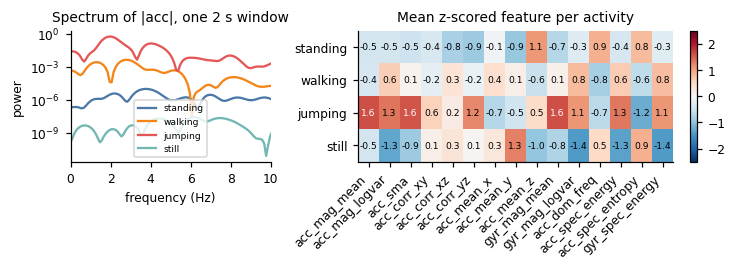

,standing,walking,jumping,still
median dominant frequency (Hz),6.54,1.46,2.05,5.66


In [5]:
# What the features look like per activity (z-scored with the training statistics)
mu_all, sd_all = fit_zscore(train_seqs, ALL)
Zall = np.vstack([s["F"] for s in train_seqs]); Zall = (Zall - mu_all) / sd_all
Yall = np.concatenate([s["y"] for s in train_seqs])

def heatmap(ax, M, xlabels, ylabels, fmt="{:.2f}", cmap="Blues", vmin=None, vmax=None, fontsize=6):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(xlabels, rotation=45, ha="right")
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(ylabels)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            rgba = im.cmap(im.norm(M[i, j]))
            lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", color="white" if lum < 0.5 else "black", fontsize=fontsize)
    return im

fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.8, 2.5), gridspec_kw={"width_ratios": [1, 1.7]})
for k, act in enumerate(ACTIVITIES):
    r = next(r for r in train_recs if r["name"].startswith(act + "_"))
    mid = len(r["X"]) // 2 - 50
    f, P = power_spectrum(np.linalg.norm(r["X"][mid:mid + 100, :3], axis=1), FS)
    a1.semilogy(f, P + 1e-12, color=STATE_COLORS[k], label=act)
a1.set_xlim(0, 10); a1.set_xlabel("frequency (Hz)"); a1.set_ylabel("power"); a1.legend(fontsize=6)
a1.set_title("Spectrum of |acc|, one 2 s window")
means = np.array([Zall[Yall == k].mean(axis=0) for k in range(K)])
im = heatmap(a2, means, FEATURE_NAMES, ACTIVITIES, fmt="{:.1f}", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
a2.set_title("Mean z-scored feature per activity"); fig.colorbar(im, ax=a2, fraction=0.025)
fig.tight_layout(); savefig(fig, "features_overview"); plt.show()

dom = pd.DataFrame({"median dominant frequency (Hz)": [np.median(np.vstack([s["F"] for s in train_seqs])[Yall == k, FEATURE_NAMES.index("acc_dom_freq")]) for k in range(K)]}, index=ACTIVITIES)
display(dom.round(2).T)

## 3. The model

- **Hidden states:** standing, walking, jumping, still.
- **Observations:** the z-scored feature vector of each window.
- **Start probabilities:** which activity a recording begins in.
- **Transition probabilities:** the chance of moving from one activity to another between consecutive windows.
- **Emission probabilities:** a Gaussian per state, with one mean and one variance per feature (diagonal covariance). A full covariance would need 120 numbers per state for 15 features, and I only have about 100 windows per activity, so diagonal is the safer choice. The price is that it ignores how features move together.

**Why Baum-Welch.** I don't observe the path of hidden states directly in the model's equations, so the parameters can't be counted off. Baum-Welch is EM for HMMs: forward-backward gives the expected state occupancy and expected transitions, and the parameters are then re-estimated in closed form. The likelihood can only go up, so "stop when it stops improving" is a natural stopping rule.

**Why Viterbi.** For a recording I want the single most likely sequence of activities. Viterbi finds it by dynamic programming in O(T K^2). It beats labelling each window on its own because it can use the transition probabilities to smooth out one-off mistakes.

Everything is done in log space so the long products of small probabilities don't underflow. Training starts from the labelled windows (class means and variances, label-counted transitions). Baum-Welch only finds a local optimum, and starting there keeps the states attached to their activity names. Section 5 also tries random starts for comparison.

In [6]:
def logsumexp(a, axis=None):
    a = np.asarray(a, dtype=float)
    amax = np.max(a, axis=axis, keepdims=True)
    amax = np.where(np.isfinite(amax), amax, 0.0)
    return np.squeeze(np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True)) + amax, axis=axis)

class GaussianHMM:
    """HMM with diagonal Gaussian emissions. Baum-Welch to train, Viterbi to decode, all in log space."""

    def __init__(self, n_states, n_features, var_floor=5e-3, trans_pseudo=0.1):
        self.K, self.D = n_states, n_features
        self.var_floor, self.trans_pseudo = var_floor, trans_pseudo
        self.pi = np.full(self.K, 1 / self.K)
        self.A = np.full((self.K, self.K), 1 / self.K)
        self.mu = np.zeros((self.K, self.D)); self.var = np.ones((self.K, self.D))
        self.history, self.converged, self.n_iter, self.max_drop = [], False, 0, 0.0

    def _logs(self):
        return np.log(np.maximum(self.pi, 1e-300)), np.log(np.maximum(self.A, 1e-300))

    def _log_emission(self, X):
        """log P(x_t | state k) for every window and state, shape (T, K)"""
        diff = X[:, None, :] - self.mu[None]
        return -0.5 * (np.sum(np.log(2 * np.pi * self.var), axis=1)[None] + np.sum(diff ** 2 / self.var[None], axis=2))

    def _forward(self, logB):
        T = len(logB); log_pi, log_A = self._logs()
        la = np.empty((T, self.K)); la[0] = log_pi + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + log_A, axis=0)
        return la, logsumexp(la[-1])

    def _backward(self, logB):
        T = len(logB); _, log_A = self._logs()
        lb = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(log_A + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
        return lb

    def init_from_labels(self, seqs, smooth=1.0):
        X = np.vstack([s["Z"] for s in seqs]); y = np.concatenate([s["y"] for s in seqs])
        for k in range(self.K):
            self.mu[k] = X[y == k].mean(axis=0)
            self.var[k] = np.maximum(X[y == k].var(axis=0), self.var_floor)
        A, pi = np.full((self.K, self.K), smooth), np.full(self.K, smooth)
        for s in seqs:
            pi[s["y"][0]] += 1
            for a, b in zip(s["y"][:-1], s["y"][1:]):
                A[a, b] += 1
        self.pi, self.A = pi / pi.sum(), A / A.sum(axis=1, keepdims=True)

    def init_random(self, seqs, rng):
        X = np.vstack([s["Z"] for s in seqs])
        self.mu = X[rng.choice(len(X), self.K, replace=False)].copy()
        self.var = np.tile(X.var(axis=0), (self.K, 1))
        self.A = rng.dirichlet(np.ones(self.K), size=self.K)
        self.pi = np.full(self.K, 1 / self.K)

    def fit(self, seqs, max_iter=300, tol=1e-6):
        """Baum-Welch. Stops when the average log-likelihood per window improves by less than tol."""
        n_windows = sum(len(s["Z"]) for s in seqs)
        self.history, self.converged, self.max_drop = [], False, 0.0
        for it in range(max_iter):
            _, log_A = self._logs()
            pi_acc = np.zeros(self.K); A_acc = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K); gx = np.zeros((self.K, self.D)); gxx = np.zeros((self.K, self.D))
            total_ll = 0.0
            for s in seqs:                                            # E-step
                X = s["Z"]; logB = self._log_emission(X)
                la, ll = self._forward(logB); lb = self._backward(logB)
                gamma = np.exp(la + lb - ll)                          # P(state at t | whole sequence)
                total_ll += ll
                pi_acc += gamma[0]
                if len(X) > 1:                                        # P(state i at t, state j at t+1 | whole sequence)
                    log_xi = la[:-1, :, None] + log_A[None] + (logB[1:] + lb[1:])[:, None, :] - ll
                    A_acc += np.exp(log_xi).sum(axis=0)
                g_sum += gamma.sum(axis=0); gx += gamma.T @ X; gxx += gamma.T @ (X ** 2)
            self.history.append(total_ll / n_windows)
            if it > 0:
                delta = self.history[-1] - self.history[-2]
                self.max_drop = max(self.max_drop, -delta)
                if delta < -1e-4:
                    warnings.warn(f"log-likelihood dropped by {-delta:.1e} at iteration {it}")
                if abs(delta) < tol:
                    self.converged = True
                    break
            self.pi = (pi_acc + 1e-3) / (pi_acc + 1e-3).sum()         # M-step
            A = A_acc + self.trans_pseudo
            self.A = A / A.sum(axis=1, keepdims=True)
            self.mu = gx / (g_sum[:, None] + 1e-12)
            self.var = np.maximum(gxx / (g_sum[:, None] + 1e-12) - self.mu ** 2, self.var_floor)
        self.n_iter = it + 1
        return self

    def viterbi(self, X):
        log_pi, log_A = self._logs(); logB = self._log_emission(X)
        T = len(X)
        delta = np.empty((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = log_pi + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + log_A
            psi[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + logB[t]
        path = np.empty(T, dtype=int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

    def predict_framewise(self, X):
        """Each window on its own, no transitions. Used as a baseline."""
        return self._log_emission(X).argmax(axis=1)

To check the implementation I compared it with brute force on a tiny model (3 states, 5 steps, so all 243 paths can be listed).

In [7]:
def sanity_check():
    r = np.random.default_rng(0)
    K_, T_ = 3, 5
    h = GaussianHMM(K_, 2)
    h.pi = r.dirichlet(np.ones(K_)); h.A = r.dirichlet(np.ones(K_), size=K_)
    h.mu = r.normal(size=(K_, 2)); h.var = r.uniform(0.5, 1.5, (K_, 2))
    X = r.normal(size=(T_, 2)); logB = h._log_emission(X)
    scores, best, best_path = [], -np.inf, None
    for path in product(range(K_), repeat=T_):
        lp = np.log(h.pi[path[0]]) + logB[0, path[0]]
        for t in range(1, T_):
            lp += np.log(h.A[path[t - 1], path[t]]) + logB[t, path[t]]
        scores.append(lp)
        if lp > best:
            best, best_path = lp, path
    la, ll = h._forward(logB); lb = h._backward(logB)
    assert abs(ll - logsumexp(np.array(scores))) < 1e-9
    assert tuple(h.viterbi(X)) == best_path
    assert np.allclose(np.exp(la + lb - ll).sum(axis=1), 1.0)
    print("forward likelihood, Viterbi path and posteriors all match brute force")

sanity_check()

forward likelihood, Viterbi path and posteriors all match brute force


## 4. Choosing the features

I wasn't sure about the orientation features (`acc_mean_x/y/z`). They separate a flat phone from an upright one, but that is how I held the phone, not what I was doing. In my recordings, standing is upright in one take and flat in the multi-activity session, so they could mislead the model.

To decide without touching the test files, I compare a few feature sets using training data only, in two ways:

- **Blocked 3-fold CV:** the 8 s pieces of each recording are split into three consecutive blocks, and each block is held out in turn.
- **Session hold-out:** train on everything except the multi-activity session, then decode the session. It is the only data with all four activities and real switches.

Both come from the same phone and day as training, so they are cheaper tests than the ones in section 6, but good enough to compare options. The assignment asks for more than three time-domain and more than one frequency-domain feature, so only sets that satisfy that can be chosen. The other sets are in the table to see what each group of features adds.

In [8]:
def accuracy_of(cols, tr, te, floor=5e-3):
    mu, sd = fit_zscore(tr, cols)
    trz, tez = apply_zscore(tr, mu, sd, cols), apply_zscore(te, mu, sd, cols)
    m = GaussianHMM(K, len(cols), var_floor=floor); m.init_from_labels(trz); m.fit(trz)
    yt = np.concatenate([s["y"] for s in tez]); yp = np.concatenate([m.viterbi(s["Z"]) for s in tez])
    return float((yt == yp).mean())

def blocked_folds(seqs, n_folds=3):
    by_rec = {}
    for s in seqs:
        act, rec, _ = s["name"].split("_")
        by_rec.setdefault((act, rec), []).append(s)
    fold = {}
    for lst in by_rec.values():
        lst.sort(key=lambda s: s["name"])
        for i, s in enumerate(lst):
            fold[s["name"]] = min(n_folds - 1, i * n_folds // len(lst))
    return fold

pieces = [s for s in train_seqs if not s["name"].startswith("session")]
session = [s for s in train_seqs if s["name"].startswith("session")]
FOLD = blocked_folds(pieces)

def cv_accuracy(cols, floor=5e-3):
    accs = []
    for f in range(3):
        accs.append(accuracy_of(cols, [s for s in pieces if FOLD[s["name"]] != f],
                                [s for s in pieces if FOLD[s["name"]] == f], floor))
    return float(np.mean(accs))

idx = {n: i for i, n in enumerate(FEATURE_NAMES)}
ORIENT = [idx[n] for n in ["acc_mean_x", "acc_mean_y", "acc_mean_z"]]
FREQ = [idx[n] for n in ["acc_dom_freq", "acc_spec_energy", "acc_spec_entropy", "gyr_spec_energy"]]
FEATURE_SETS = {"all 15": ALL,
                "without orientation (12)": [i for i in ALL if i not in ORIENT],
                "without frequency (11)": [i for i in ALL if i not in FREQ],
                "time-domain only, no orientation (8)": [i for i in ALL if i not in ORIENT + FREQ],
                "frequency only (4)": FREQ}
rows = []
for name, cols in FEATURE_SETS.items():
    rows.append(dict(feature_set=name, blocked_cv=cv_accuracy(cols), session_holdout=accuracy_of(cols, pieces, session)))
ablation = pd.DataFrame(rows).set_index("feature_set")
ablation["mean"] = ablation.mean(axis=1)

ablation.insert(0, "time features", [len([c for c in FEATURE_SETS[n] if c not in FREQ]) for n in ablation.index])
ablation.insert(1, "freq features", [len([c for c in FEATURE_SETS[n] if c in FREQ]) for n in ablation.index])
display(ablation.round(3))

# the assignment asks for more than 3 time-domain and more than 1 frequency-domain feature
eligible = ablation[(ablation["time features"] > 3) & (ablation["freq features"] > 1)]
chosen = eligible["mean"].idxmax()
COLS = FEATURE_SETS[chosen]
FEATURES = [FEATURE_NAMES[i] for i in COLS]
print(f"Chosen feature set (best of the sets that meet the assignment's feature requirement): {chosen}")

,time features,freq features,blocked_cv,session_holdout,mean
feature_set,,,,,
all 15,11,4,1.000,0.769,0.885
without orientation (12),8,4,0.991,0.942,0.967
without frequency (11),11,0,1.000,0.769,0.885
"time-domain only, no orientation (8)",8,0,0.991,0.942,0.967
frequency only (4),0,4,0.995,1.000,0.998


Chosen feature set (best of the sets that meet the assignment's feature requirement): without orientation (12)


The variance floor stops a state's variance from collapsing, and 5e-3 was my starting guess. Here is how much the choice matters.

In [9]:
floors = pd.DataFrame([dict(variance_floor=f, blocked_cv=cv_accuracy(COLS, f), session_holdout=accuracy_of(COLS, pieces, session, f))
                       for f in [1e-3, 5e-3, 2e-2, 5e-2]]).set_index("variance_floor")
display(floors.round(3))

,blocked_cv,session_holdout
variance_floor,,
0.001,0.991,0.942
0.005,0.991,0.942
0.020,0.995,0.942
0.050,0.998,0.731


## 5. Training

The final model is trained on all training files with the chosen features, z-scored with training statistics only. Training from the labelled windows barely has anywhere to go, because that start is already close to the optimum. To show Baum-Welch really does the climbing, I also train from five random starts (random windows as means, random transition matrix).

labelled start: Baum-Welch converged after 10 iterations, average log-likelihood per window -0.659 -> -0.518


largest dip in the likelihood from one iteration to the next: 0.0e+00 (it should be 0; the variance floor and the transition smoothing could cause tiny dips)


,iterations,final avg log-lik,state purity
start,,,
labels,10,-0.518,0.984
random 0,8,-0.518,0.984
random 1,27,-3.929,0.755
random 2,10,-2.993,0.746
random 3,13,-2.993,0.746
random 4,9,-0.518,0.984


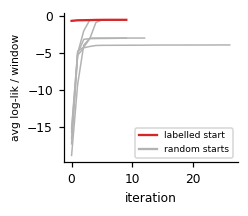

In [10]:
mu_tr, sd_tr = fit_zscore(train_seqs, COLS)
trainZ = apply_zscore(train_seqs, mu_tr, sd_tr, COLS)
D = len(COLS)

hmm = GaussianHMM(K, D)
hmm.init_from_labels(trainZ)
hmm.fit(trainZ)
print(f"labelled start: Baum-Welch {'converged' if hmm.converged else 'stopped at max_iter'} after {hmm.n_iter} iterations, "
      f"average log-likelihood per window {hmm.history[0]:.3f} -> {hmm.history[-1]:.3f}")


def purity(model):
    """How cleanly each learned state maps onto one real activity (1 = perfectly)."""
    yt = np.concatenate([s["y"] for s in trainZ]); yp = np.concatenate([model.viterbi(s["Z"]) for s in trainZ])
    counts = np.zeros((K, K), int); np.add.at(counts, (yp, yt), 1)
    return counts.max(axis=1).sum() / counts.sum()

rand_models = []
for seed in range(5):
    m = GaussianHMM(K, D); m.init_random(trainZ, np.random.default_rng(seed)); m.fit(trainZ)
    rand_models.append(m)
print(f"largest dip in the likelihood from one iteration to the next: {max(m.max_drop for m in [hmm] + rand_models):.1e} "
      "(it should be 0; the variance floor and the transition smoothing could cause tiny dips)")
display(pd.DataFrame({"start": ["labels"] + [f"random {i}" for i in range(5)],
                      "iterations": [hmm.n_iter] + [m.n_iter for m in rand_models],
                      "final avg log-lik": [hmm.history[-1]] + [m.history[-1] for m in rand_models],
                      "state purity": [purity(hmm)] + [purity(m) for m in rand_models]}).set_index("start").round(3))

fig, ax = plt.subplots(figsize=(2.3, 2.0))
for m in rand_models:
    ax.plot(m.history, color="0.7", lw=1)
ax.plot(hmm.history, color="C3", lw=1.5, label="labelled start")
ax.plot([], [], color="0.7", label="random starts")
ax.set_xlabel("iteration"); ax.set_ylabel("avg log-lik / window", fontsize=7); ax.legend(fontsize=6)
fig.tight_layout(); savefig(fig, "convergence"); plt.show()

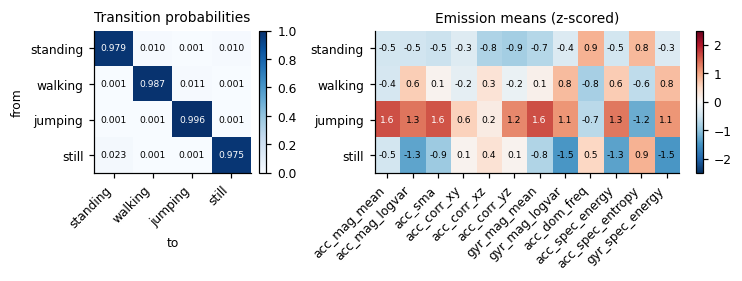

start probabilities: {'standing': np.float64(0.286), 'walking': np.float64(0.25), 'jumping': np.float64(0.214), 'still': np.float64(0.25)}
expected time in a state before leaving it: {'standing': '47 s', 'walking': '77 s', 'jumping': '275 s', 'still': '40 s'}
variances at the floor: 10 of 48


In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.8, 2.6), gridspec_kw={"width_ratios": [1, 1.9]})
im1 = heatmap(a1, hmm.A, ACTIVITIES, ACTIVITIES, fmt="{:.3f}", cmap="Blues", vmin=0, vmax=1)
a1.set_xlabel("to"); a1.set_ylabel("from"); a1.set_title("Transition probabilities"); fig.colorbar(im1, ax=a1, fraction=0.046)
im2 = heatmap(a2, hmm.mu, FEATURES, ACTIVITIES, fmt="{:.1f}", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
a2.set_title("Emission means (z-scored)"); fig.colorbar(im2, ax=a2, fraction=0.025)
fig.tight_layout(); savefig(fig, "transition_emission"); plt.show()

print("start probabilities:", dict(zip(ACTIVITIES, hmm.pi.round(3))))
step_s = WIN_S * (1 - OVERLAP)
print("expected time in a state before leaving it:",
      {a: f"{step_s / max(1 - hmm.A[k, k], 1e-9):.0f} s" for k, a in enumerate(ACTIVITIES)})
print("variances at the floor:", int((hmm.var <= hmm.var_floor * 1.001).sum()), "of", hmm.var.size)

## 6. Testing on unseen recordings

The test files were never used for training, for the z-score statistics, or for choosing features.

- **Test A:** a friend's iPhone 11, recorded at school on the same day as training: three 8 s files per activity cut from the middle of longer recordings.
- **Test B:** the next day, at home, with two other friends' phones (iPhone 16 Pro for jumping and still, a Samsung SM-A235F for standing and walking). Each is one short recording, used as a whole. The Android values were converted to the iPhone convention (g, opposite sign) before anything else.

Sensitivity is the share of windows of an activity that the model finds. Specificity is the share of windows of *other* activities that it correctly leaves alone. Both are computed per activity, window by window, with 95 % Wilson intervals because the counts are small.

In [12]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

def confusion(yt, yp):
    cm = np.zeros((K, K), dtype=int); np.add.at(cm, (yt, yp), 1); return cm

def metrics_table(cm):
    total, rows = cm.sum(), []
    for k, act in enumerate(ACTIVITIES):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = total - TP - FN - FP
        s, sp = wilson(TP, TP + FN), wilson(TN, TN + FP)
        rows.append(dict(activity=act, windows=int(cm[k].sum()),
                         sensitivity=TP / (TP + FN) if TP + FN else np.nan, sens_low=s[0], sens_high=s[1],
                         specificity=TN / (TN + FP) if TN + FP else np.nan, spec_low=sp[0], spec_high=sp[1]))
    return pd.DataFrame(rows).set_index("activity")

def show_metrics(df):
    out = pd.DataFrame({"windows": df["windows"],
                        "sensitivity": [f"{a:.2f} ({b:.2f}-{c:.2f})" for a, b, c in zip(df.sensitivity, df.sens_low, df.sens_high)],
                        "specificity": [f"{a:.2f} ({b:.2f}-{c:.2f})" for a, b, c in zip(df.specificity, df.spec_low, df.spec_high)]})
    display(out)

testZ = apply_zscore(test_seqs, mu_tr, sd_tr, COLS)
for s in testZ:
    s["pred"] = hmm.viterbi(s["Z"])

results, cms = [], {}
for label, group in [("Test A (iPhone 11, same day)", "A"), ("Test B (other phones, next day)", "B"), ("A + B", None)]:
    sub = [s for s in testZ if group is None or s["group"] == group]
    yt, yp = np.concatenate([s["y"] for s in sub]), np.concatenate([s["pred"] for s in sub])
    yf = np.concatenate([hmm.predict_framewise(s["Z"]) for s in sub])
    cm = confusion(yt, yp); cms[group] = cm
    acc, (lo, hi) = (yt == yp).mean(), wilson(int((yt == yp).sum()), len(yt))
    print(f"\n{label}: {len(sub)} files, {len(yt)} windows")
    print(f"overall accuracy {acc:.3f} (95% CI {lo:.2f}-{hi:.2f});  without transitions (window by window): {(yt == yf).mean():.3f}")
    show_metrics(metrics_table(cm))
    results.append(metrics_table(cm).assign(set=label, overall_accuracy=acc))
pd.concat(results).round(4).to_csv(FIG_DIR / "test_metrics.csv")

wrong = [(s["name"], i, ACTIVITIES[s["y"][i]], ACTIVITIES[s["pred"][i]]) for s in testZ for i in np.where(s["pred"] != s["y"])[0]]
print("\nmisclassified windows:", wrong if wrong else "none")
def gap(s, i):
    top2 = np.sort(hmm._log_emission(s["Z"])[i])[::-1][:2]
    return top2[0] - top2[1]
margins = {a: min(gap(s, i) for s in testZ for i in np.where(s["y"] == k)[0]) for k, a in enumerate(ACTIVITIES)}
print("smallest gap between best and second-best state (log-likelihood) per activity:", {a: round(float(v), 1) for a, v in margins.items()})


Test A (iPhone 11, same day): 12 files, 84 windows
overall accuracy 1.000 (95% CI 0.96-1.00);  without transitions (window by window): 1.000


,windows,sensitivity,specificity
activity,,,
standing,21,1.00 (0.85-1.00),1.00 (0.94-1.00)
walking,21,1.00 (0.85-1.00),1.00 (0.94-1.00)
jumping,21,1.00 (0.85-1.00),1.00 (0.94-1.00)
still,21,1.00 (0.85-1.00),1.00 (0.94-1.00)



Test B (other phones, next day): 4 files, 23 windows
overall accuracy 1.000 (95% CI 0.86-1.00);  without transitions (window by window): 1.000


,windows,sensitivity,specificity
activity,,,
standing,7,1.00 (0.65-1.00),1.00 (0.81-1.00)
walking,7,1.00 (0.65-1.00),1.00 (0.81-1.00)
jumping,4,1.00 (0.51-1.00),1.00 (0.83-1.00)
still,5,1.00 (0.57-1.00),1.00 (0.82-1.00)



A + B: 16 files, 107 windows
overall accuracy 1.000 (95% CI 0.97-1.00);  without transitions (window by window): 1.000


,windows,sensitivity,specificity
activity,,,
standing,28,1.00 (0.88-1.00),1.00 (0.95-1.00)
walking,28,1.00 (0.88-1.00),1.00 (0.95-1.00)
jumping,25,1.00 (0.87-1.00),1.00 (0.96-1.00)
still,26,1.00 (0.87-1.00),1.00 (0.95-1.00)



misclassified windows: none
smallest gap between best and second-best state (log-likelihood) per activity: {'standing': 21.6, 'walking': 61.7, 'jumping': 28.1, 'still': 30.5}


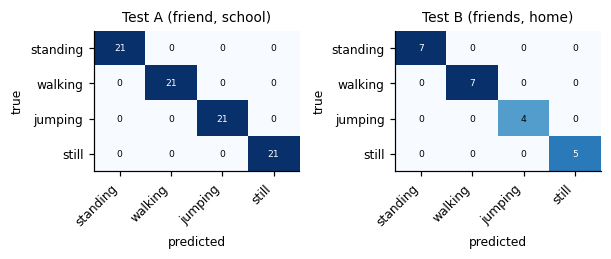

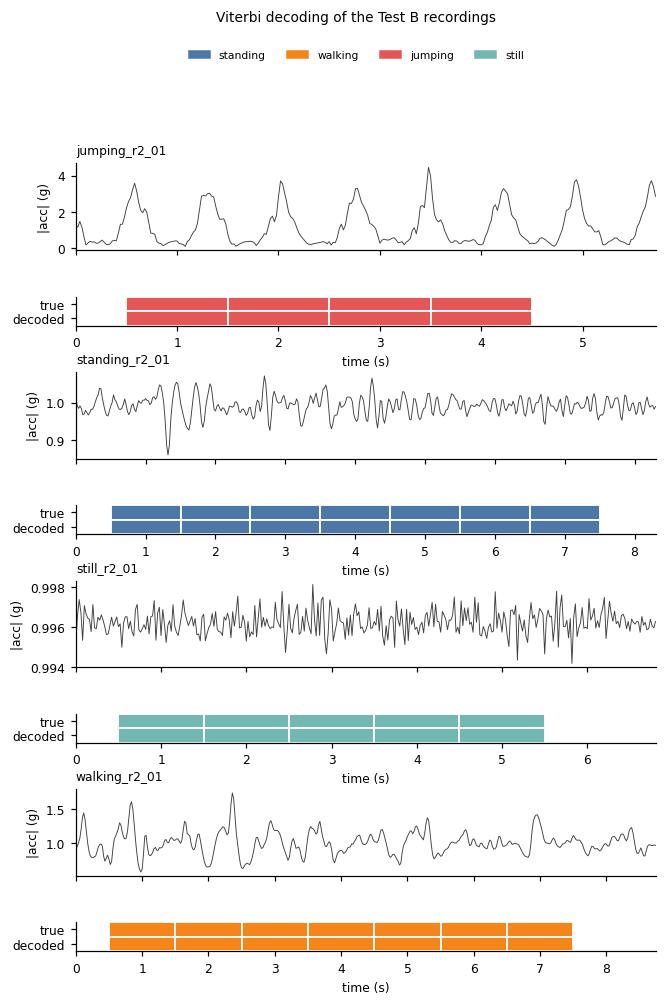

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.4))
for ax, (g, title) in zip(axes, [("A", "Test A (friend, school)"), ("B", "Test B (friends, home)")]):
    heatmap(ax, cms[g], ACTIVITIES, ACTIVITIES, fmt="{:d}", cmap="Blues")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
fig.tight_layout(); savefig(fig, "confusion_test"); plt.show()

def plot_decoded(seqs, title, fname):
    n = len(seqs)
    fig = plt.figure(figsize=(6.8, 2.2 * n + 0.5))
    gs = fig.add_gridspec(2 * n, 1, height_ratios=[3, 1] * n, hspace=0.8)
    for i, s in enumerate(seqs):
        r = s["rec"]
        a_sig = fig.add_subplot(gs[2 * i]); a_str = fig.add_subplot(gs[2 * i + 1], sharex=a_sig)
        a_sig.plot(r["t"], np.linalg.norm(r["X"][:, :3], axis=1), lw=0.6, color="0.25")
        a_sig.set_ylabel("|acc| (g)"); a_sig.set_title(s["name"], fontsize=8, loc="left")
        plt.setp(a_sig.get_xticklabels(), visible=False)
        for row, arr in enumerate([s["y"], s["pred"]]):
            a_str.bar(s["centers"], 1, width=s["step_s"], bottom=1 - row, linewidth=1.2, edgecolor="white",
                      color=[STATE_COLORS[k] for k in arr])
        a_str.set_ylim(0, 2); a_str.set_yticks([1.5, 0.5]); a_str.set_yticklabels(["true", "decoded"])
        a_str.set_xlabel("time (s)"); a_sig.set_xlim(0, r["t"][-1])
    fig.legend(handles=[Patch(color=c, label=a) for c, a in zip(STATE_COLORS, ACTIVITIES)],
               loc="upper center", ncol=K, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title, y=1.03, fontsize=9); savefig(fig, fname); plt.show()

plot_decoded([s for s in testZ if s["group"] == "B"], "Viterbi decoding of the Test B recordings", "decoded_test")

### The session as a harder check

The multi-activity session is the only recording with all four activities and real switches, but it is part of the training set above. So here I train a second model **without** it and decode it as an unseen sequence. It is the same phone and day as training, so it is a gentler test than A and B, but it is the only one where the model has to find the changes between activities.

session accuracy 0.942 on 52 windows (window by window, no transitions: 0.923)


,pred standing,pred walking,pred jumping,pred still
true standing,12,0,0,0
true walking,0,16,0,0
true jumping,0,0,11,0
true still,3,0,0,10


wrong windows (centre time in s): [(12.0, 'still', '->', 'standing'), (13.0, 'still', '->', 'standing'), (14.0, 'still', '->', 'standing')]


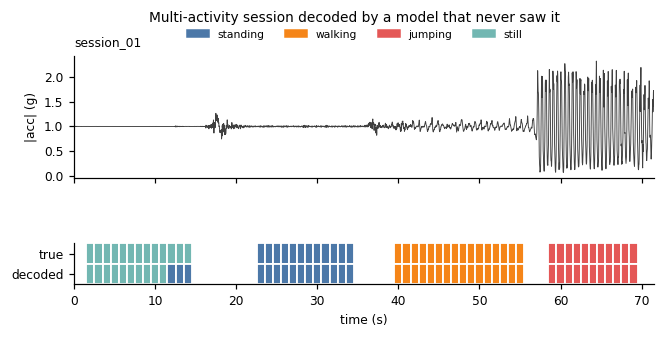

In [14]:
mu_s, sd_s = fit_zscore(pieces, COLS)
m_s = GaussianHMM(K, D); m_s.init_from_labels(apply_zscore(pieces, mu_s, sd_s, COLS)); m_s.fit(apply_zscore(pieces, mu_s, sd_s, COLS))
sessZ = apply_zscore(session, mu_s, sd_s, COLS)
for s in sessZ:
    s["pred"] = m_s.viterbi(s["Z"])
yt, yp = np.concatenate([s["y"] for s in sessZ]), np.concatenate([s["pred"] for s in sessZ])
yf = np.concatenate([m_s.predict_framewise(s["Z"]) for s in sessZ])
print(f"session accuracy {(yt == yp).mean():.3f} on {len(yt)} windows (window by window, no transitions: {(yt == yf).mean():.3f})")
display(pd.DataFrame(confusion(yt, yp), index=[f"true {a}" for a in ACTIVITIES], columns=[f"pred {a}" for a in ACTIVITIES]))
for s in sessZ:
    bad = np.where(s["pred"] != s["y"])[0]
    print("wrong windows (centre time in s):", [(round(float(s["centers"][i]), 1), ACTIVITIES[s["y"][i]], "->", ACTIVITIES[s["pred"][i]]) for i in bad])
plot_decoded(sessZ, "Multi-activity session decoded by a model that never saw it", "decoded_session_holdout")

### Baum-Welch without the labels

So far the model started from the labelled windows. To see whether Baum-Welch can find the activities on its own, I train 10 models from random starts and keep the one with the best likelihood on the training data, which needs no labels. The labels are used for one thing only: giving the learned states their names, by majority vote on the training windows. The result is compared with the labelled start on every check.

In [15]:
def state_counts(model, seqs_z):
    counts = np.zeros((K, K), int)                      # rows: learned state, columns: real activity
    for s in seqs_z:
        np.add.at(counts, (model.viterbi(s["Z"]), s["y"]), 1)
    return counts

def unsupervised_model(seqs_z, n_starts=10):
    models = []
    for seed in range(n_starts):
        m = GaussianHMM(K, D); m.init_random(seqs_z, np.random.default_rng(seed)); m.fit(seqs_z)
        models.append(m)
    best = max(models, key=lambda m: m.history[-1])     # chosen by likelihood alone
    counts = state_counts(best, seqs_z)
    names = counts.argmax(axis=1)                       # state -> activity, the only use of the labels
    table = pd.DataFrame({"avg log-lik": [m.history[-1] for m in models],
                          "state purity": [state_counts(m, seqs_z).max(axis=1).sum() / counts.sum() for m in models]},
                         index=[f"start {i}" for i in range(n_starts)]).sort_values("avg log-lik", ascending=False)
    return best, names, table, len(set(names)) == K

def accuracy_with(model, names, seqs_z):
    yt = np.concatenate([s["y"] for s in seqs_z])
    yp = np.concatenate([names[model.viterbi(s["Z"])] for s in seqs_z])
    return (yt == yp).mean()

def accuracy_of_preds(seqs_z):
    return np.mean(np.concatenate([s["pred"] == s["y"] for s in seqs_z]))

u_full, names_full, table_full, ok_full = unsupervised_model(trainZ)
piecesZ = apply_zscore(pieces, mu_s, sd_s, COLS)
u_sess, names_sess, _, ok_sess = unsupervised_model(piecesZ)
display(table_full.round(3))
print(f"{int((table_full['state purity'] > 0.95).sum())} of 10 random starts ended up with the four activities cleanly separated, "
      "and the best likelihood is one of them. Every state of the chosen model got its own activity name:", ok_full and ok_sess)

A_Z = [s for s in testZ if s["group"] == "A"]; B_Z = [s for s in testZ if s["group"] == "B"]
display(pd.DataFrame({
    "labelled start": [accuracy_of_preds(A_Z), accuracy_of_preds(B_Z), accuracy_of_preds(sessZ)],
    "best of 10 random starts": [accuracy_with(u_full, names_full, A_Z), accuracy_with(u_full, names_full, B_Z),
                                 accuracy_with(u_sess, names_sess, sessZ)]},
    index=["test A", "test B", "session held out"]).round(3))

,avg log-lik,state purity
start 7,-0.517,0.959
start 0,-0.518,0.984
start 4,-0.518,0.984
start 9,-2.954,0.746
start 2,-2.993,0.746
start 3,-2.993,0.746
start 5,-3.069,0.746
start 6,-3.833,0.783
start 1,-3.929,0.755
start 8,-4.026,0.771


3 of 10 random starts ended up with the four activities cleanly separated, and the best likelihood is one of them. Every state of the chosen model got its own activity name: True


,labelled start,best of 10 random starts
test A,1.000,1.000
test B,1.000,1.000
session held out,0.942,0.942


## 7. Noise and sampling rate

Two quick experiments on the test files (A and B together), each retraining from scratch where the pipeline changes:

- **Noise:** Gaussian noise added to the test signals only (accelerometer in g, a tenth of that on the gyroscope).
- **Sampling rate:** training and test data block-averaged from 50 Hz down to 25 and 10 Hz.

,accuracy,still sensitivity
noise sd (g),,
0.000,1.000,1.0
0.002,0.757,0.0
0.005,0.757,0.0
0.010,0.757,0.0
0.020,0.757,0.0


,accuracy
rate (Hz),
50,1.0
25,1.0
10,1.0


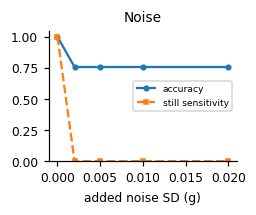

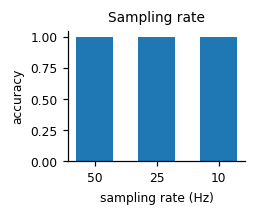

In [16]:
def run_pipeline(factor=1, noise_sd=0.0, seed=0):
    tr = build_sequences(train_recs, factor)
    mu, sd = fit_zscore(tr, COLS); trz = apply_zscore(tr, mu, sd, COLS)
    te = apply_zscore(build_sequences(test_recs, factor, noise_sd, np.random.default_rng(seed)), mu, sd, COLS)
    m = GaussianHMM(K, len(COLS)); m.init_from_labels(trz); m.fit(trz)
    yt = np.concatenate([s["y"] for s in te]); yp = np.concatenate([m.viterbi(s["Z"]) for s in te])
    return (yt == yp).mean(), confusion(yt, yp)

noise_levels = [0.0, 0.002, 0.005, 0.01, 0.02]
noise_res = [run_pipeline(1, sd) for sd in noise_levels]
rate_factors = [1, 2, 5]
rate_res = [run_pipeline(f) for f in rate_factors]

noise_df = pd.DataFrame({"noise sd (g)": noise_levels, "accuracy": [a for a, _ in noise_res],
                         "still sensitivity": [cm[3, 3] / cm[3].sum() for _, cm in noise_res]}).set_index("noise sd (g)")
rate_df = pd.DataFrame({"rate (Hz)": [FS // f for f in rate_factors], "accuracy": [a for a, _ in rate_res]}).set_index("rate (Hz)")
display(noise_df.round(3)); display(rate_df.round(3))

fig, a1 = plt.subplots(figsize=(2.3, 2.0))
a1.plot(noise_levels, noise_df["accuracy"], "o-", ms=3, label="accuracy")
a1.plot(noise_levels, noise_df["still sensitivity"], "s--", ms=3, label="still sensitivity")
a1.set_ylim(0, 1.05); a1.set_xlabel("added noise SD (g)"); a1.legend(fontsize=6, loc="center right"); a1.set_title("Noise")
fig.tight_layout(); savefig(fig, "robustness_noise"); plt.show()

fig, a2 = plt.subplots(figsize=(2.3, 2.0))
a2.bar([str(r) for r in rate_df.index], rate_df["accuracy"], width=0.6); a2.set_ylim(0, 1.05)
a2.set_xlabel("sampling rate (Hz)"); a2.set_ylabel("accuracy"); a2.set_title("Sampling rate")
fig.tight_layout(); savefig(fig, "robustness_rate"); plt.show()

## 8. Notes for the report

In [17]:
cm_all = cms[None]
off = sorted([(int(cm_all[i, j]), ACTIVITIES[i], ACTIVITIES[j]) for i in range(K) for j in range(K)
              if i != j and cm_all[i, j] > 0], reverse=True)
print("most confused pairs on the test files (true -> predicted):", off[:3] if off else "none")
print("\nlearned transition matrix:")
display(pd.DataFrame(hmm.A, index=ACTIVITIES, columns=ACTIVITIES).round(3))
print("The off-diagonal entries come from the 3 switches in one session plus the boundaries between files,")
print("so they say little about how people really switch between activities.")

most confused pairs on the test files (true -> predicted): none

learned transition matrix:


,standing,walking,jumping,still
standing,0.979,0.010,0.001,0.010
walking,0.001,0.987,0.011,0.001
jumping,0.001,0.001,0.996,0.001
still,0.023,0.001,0.001,0.975


The off-diagonal entries come from the 3 switches in one session plus the boundaries between files,
so they say little about how people really switch between activities.
